### This notebook contains code for analyses of the attentional task

#### Includes relationship between attention biases and decisions + relationship w/ neural goal tracking 

Code for Figure 2e,f,g Supplementary figures 10a,b (and corresponding statistical tests)

To run this code, you need the processed behavioural data (found in the folder fmri_study/data/behav_data/processed/) and individual parameters for decision-making biases (decision_parameters.csv)

To process the raw behavioural data from scratch, open the script 'preprocess_data' in the folder 'behav_preprocessing'

Eleanor Holton, 19/01/2024

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats

import behav_functions as bf


In [2]:
# Parameters

nParticipants = 30
participants = range(nParticipants)

# plotting parameters
val_type_colours = ["#1E88E5", "#E66100"]
quartiles_colours = sns.color_palette("Purples")[:][2:6] 
model_colours = ["#D3D3D3","#D3D3D3", "#D3D3D3", quartiles_colours[3]]
bias_color='g'

small_label_fontsize = 15
medium_label_fontsize=18

In [3]:
## Import data 

base_folder = ''
data_folder = base_folder + '/data/mri_study/behaviour/'
figure_folder = ''

# Specify data folders for scan and post-scan testing sessions 
scanner_data_folder = data_folder + 'processed/scan_session/'
post_scanner_data_folder =data_folder + 'processed/post_scan_session/'

# Concatenate scanner and post-scanner data for full data set 
df_full = pd.DataFrame()
df_scanner = pd.DataFrame()
df_postscanner = pd.DataFrame()

for p in range(nParticipants):
    
    p_scanner = pd.read_csv(scanner_data_folder + 'scan_sub_' + str(p) + '.csv')
    p_postScanner = pd.read_csv(post_scanner_data_folder + 'post_scan_sub_' + str(p) + '.csv')
    
    #Merge total trials and total blocks across sessions in combined dataframe 
    scan_maxTrial = p_scanner['total_trial_number'].max()
    scan_maxBlock = p_scanner['block'].max()
    
    p_postScanner['total_trial_number']+=scan_maxTrial
    p_postScanner['block']+=scan_maxBlock
      
    df_full = pd.concat((df_full, p_scanner, p_postScanner))
    df_scanner = pd.concat((df_scanner, p_scanner))
    df_postscanner = pd.concat((df_postscanner, p_postScanner))

df_full = df_full.reset_index()
df_scanner = df_scanner.reset_index()
df_postscanner = df_postscanner.reset_index()


In [4]:
# Classify items by the PREVIOUS choice (for analysis of spatial task)
df_spatial = df_postscanner.copy()
df_spatial['sampler_switch_value']=df_spatial['sampler_best_alt']-df_spatial['sampler_goal_item']
df_spatial = bf.categorise_previous_trial(df_spatial)
demean=0
df_spatial = bf.add_spatial_contrasts(df_spatial,demean)
aggregate_spatial_df = df_spatial[['participant','netitem_err','alts_err','prevBA_err','netitem_rt','alts_rt','prevBA_rt','errDiff_net_best','errDiff_net_avg','rtDiff_net_best','rtDiff_net_avg']].groupby('participant').mean().reset_index()


/Users/eleanorholton/Dropbox/nature_human_behaviour/goal_pursuit/scripts/mri_study/behaviour/behav_functions.py:56: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df.iloc[index+1, df.columns.get_loc('prevChoice_mag')] = row[df.choice[index]-1] # index from magnitudes
/Users/eleanorholton/Dropbox/nature_human_behaviour/goal_pursuit/scripts/mri_study/behaviour/behav_functions.py:59: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  row[df.choice[index]-1] = np.nan # set previous choice to nan, to max over alternatives
/Users/eleanorholton/Dropbox/nature_human_behaviour/goal_pursuit/scripts/mri_study/behaviour/behav_fun

#### Comparing average error and RT for the current goal versus alternative goals


In [5]:

# Check assumption: normally distributed
print('check normality assumption for difference (err): ')
print(stats.normaltest(aggregate_spatial_df['alts_err']-aggregate_spatial_df['netitem_err']))

err_result = stats.ttest_rel(aggregate_spatial_df['alts_err'],aggregate_spatial_df['netitem_err'])
print('\nalt err differs from net err')
print(err_result)
print('cohend:' + str(bf.cohen_d_paired(aggregate_spatial_df['alts_err'], aggregate_spatial_df['netitem_err'])))
print(err_result.confidence_interval(.95))

print('\ncheck normality assumption (rt): ')
print(stats.normaltest(aggregate_spatial_df['alts_rt']-aggregate_spatial_df['netitem_rt']))


rt_result = stats.ttest_rel(aggregate_spatial_df['alts_rt'],aggregate_spatial_df['netitem_rt'])
print('\nalt rt differs from net rt:')
print(rt_result)
print('cohend:'+str(bf.cohen_d_paired(aggregate_spatial_df['alts_rt'], aggregate_spatial_df['netitem_rt'])))
print(rt_result.confidence_interval(.95))


check normality assumption for difference (err): 
NormaltestResult(statistic=0.13463006013573223, pvalue=0.9349006331303886)

alt err differs from net err
TtestResult(statistic=2.2482197524891347, pvalue=0.032332814864462794, df=29)
cohend:0.41748392723479777
ConfidenceInterval(low=0.000611786682129154, high=0.012939916902419163)

check normality assumption (rt): 
NormaltestResult(statistic=0.8225466542109949, pvalue=0.6628057440645909)

alt rt differs from net rt:
TtestResult(statistic=3.30012333649423, pvalue=0.002566097211554964, df=29)
cohend:0.6128175189962768
ConfidenceInterval(low=0.011976262525337358, high=0.05101416227547574)


/var/folders/z2/d_x9vksx1wg8gn4pyfl2np000000gq/T/ipykernel_31364/784520813.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(ax=ax,data=err_tab,x='variable',y='value',palette=colours, zorder=1)
/var/folders/z2/d_x9vksx1wg8gn4pyfl2np000000gq/T/ipykernel_31364/784520813.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(ax=ax,data=err_tab,x='variable',y='value',palette=colours, zorder=1)


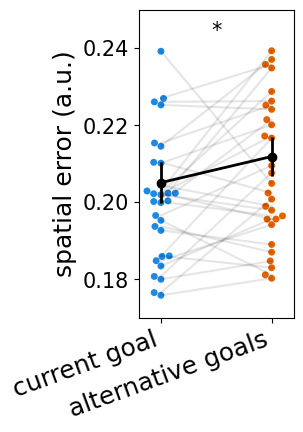

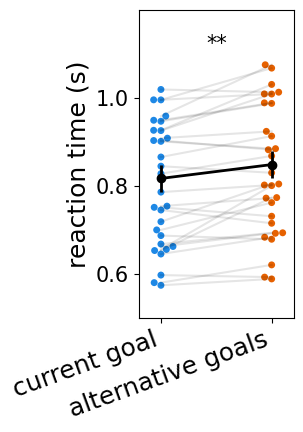

In [6]:
# Plot effect (fig.2e)

def plot_comparison(agg_df, net_item,alt_item,ylabel,statistic,colours,figsize,yticks,yticklabels,ylim,name):
    
    fig,ax=plt.subplots(figsize=[2,4])
    
    err_tab = pd.melt(agg_df, id_vars='participant', value_vars=[net_item,alt_item])
    sns.swarmplot(ax=ax,data=err_tab,x='variable',y='value',palette=colours, zorder=1)
    ax.set_yticks(yticks,yticklabels)
    ax.set_xlim([-0.2,1.2])   
    ax.set_ylim(ylim)           
    [ax.plot([0,1],[row[net_item], row[alt_item]],color='k',alpha=0.1) for index, row in agg_df.iterrows()]
    ax.errorbar([0,1],[agg_df[net_item].mean(), agg_df[alt_item].mean()],[agg_df[net_item].sem(), agg_df[alt_item].sem()],color='k',fmt='o',linestyle='-',linewidth=2)
    ax.tick_params(axis='y', which='major',labelsize=small_label_fontsize)
    ax.set_xticks([0,1],['current goal','alternative goals'],rotation=20,ha='right')
    ax.tick_params(axis='x', which='major', labelsize=medium_label_fontsize)
    ax.set_ylabel(ylabel, fontsize=medium_label_fontsize)
    ax.set_xlabel('')
    
    txt = bf.convert_pvalue_to_asterisks(statistic.pvalue)
    ax.text(0.5,(0+yticks[2])*1.1, txt, ha='center', va='bottom', fontsize=small_label_fontsize)
    
    fig.savefig(figure_folder+ name + '.png',bbox_inches='tight',dpi=300)


plot_comparison(aggregate_spatial_df, 'netitem_err','alts_err','spatial error (a.u.)',err_result,val_type_colours,[2.5,6],[0.18,0.2,0.22,0.24],['0.18','0.20','0.22','0.24'],[0.17,0.25],'spatial_acc_plot')
plot_comparison(aggregate_spatial_df, 'netitem_rt','alts_rt','reaction time (s)',rt_result,val_type_colours,[2.5,6],[0.6,0.8,1.0],['0.6','0.8','1.0'],[0.5,1.2],'spatial_rt_plot')




#### Spatial error as a function of trials invested

In [8]:
# Testing the difference between the slopes for each item 

net_err_betas=[]
alts_err_betas=[]
net_err_intercept=[]
alts_err_intercept=[]

for p in participants:
    
    # Predictor: trials invested
    exog = df_spatial.loc[(df_spatial["errDiff_net_avg"].notna()) & (df_spatial["participant"]==p),"trials_invested"]
    exog = sm.add_constant(exog)
    
    alts_endog = df_spatial.loc[(df_spatial["errDiff_net_avg"].notna()) & (df_spatial["participant"]==p),"alts_err"]
    goal_endog = df_spatial.loc[(df_spatial["errDiff_net_avg"].notna()) & (df_spatial["participant"]==p),"netitem_err"]

    acc_glm_goal = sm.GLM(goal_endog, exog, family=sm.families.Gaussian()).fit()
    acc_glm_alts = sm.GLM(alts_endog, exog, family=sm.families.Gaussian()).fit()
    
    net_err_betas.append(acc_glm_goal.params.trials_invested)
    net_err_intercept.append(acc_glm_goal.params.const)
    alts_err_betas.append(acc_glm_alts.params.trials_invested)
    alts_err_intercept.append(acc_glm_alts.params.const)

print('\ndifference between net and alternative betas (slope):')
compare_betas_stat = stats.ttest_rel(alts_err_betas, net_err_betas)
print(compare_betas_stat)
print(compare_betas_stat.confidence_interval(.95))
print('cohend' + str(bf.cohen_d_paired(np.array(net_err_betas), np.array(alts_err_betas))))

print('\ndifference between net betas and 0:')
netitem_stat= stats.ttest_1samp(net_err_betas,popmean=0)
print(netitem_stat)
print(netitem_stat.confidence_interval(0.95))
print('cohend' + str(bf.cohen_d_paired(np.array(net_err_betas), 0)))

print('\ndifference between alt betas and 0:')
altstat = stats.ttest_1samp(alts_err_betas,popmean=0)
print(altstat)
print(altstat.confidence_interval(0.95))
print('cohend' + str(bf.cohen_d_paired(np.array(alts_err_betas), 0)))


difference between net and alternative betas (slope):
TtestResult(statistic=2.374853255373871, pvalue=0.024387496728338127, df=29)
ConfidenceInterval(low=0.0003380088625896589, high=0.004532524772869055)
cohend-0.44099917837752345

difference between net betas and 0:
TtestResult(statistic=-2.6540635629647573, pvalue=0.012774068910314863, df=29)
ConfidenceInterval(low=-0.0043573138230179834, high=-0.0005645275456075155)
cohend-0.4928472308681318

difference between alt betas and 0:
TtestResult(statistic=-0.03292130413247768, pvalue=0.9739628905801606, df=29)
ConfidenceInterval(low=-0.001619395358734979, high=0.0015680876255681948)
cohend-0.006113332704110018


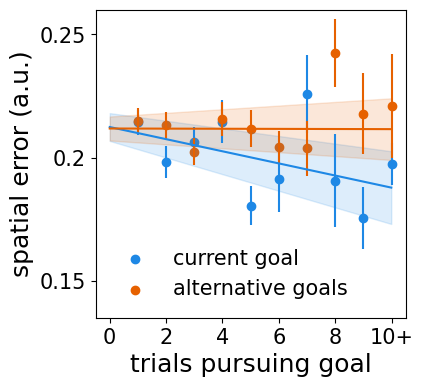

In [9]:
# Plot modulation of spatial attention by trials invested in the goal (fig.2f)

df_spatial['trials_invested_capped'] = df_spatial['trials_invested']
df_spatial.loc[df_spatial['trials_invested_capped']>10,'trials_invested_capped']=10

# Bin data by trials invested 
participant_mean_errs = df_spatial.groupby(['participant', 'trials_invested_capped'])[['netitem_err', 'alts_err']].mean().reset_index()
cross_p_errs = participant_mean_errs.groupby('trials_invested_capped').mean().reset_index()
cross_p_sems = participant_mean_errs.groupby('trials_invested_capped').sem()

# plot error bars and scatter plot
fig,ax = plt.subplots(figsize=[4,4])
ax.scatter(cross_p_errs.trials_invested_capped,cross_p_errs.netitem_err,color=val_type_colours[0],label='current goal')
ax.scatter(cross_p_errs.trials_invested_capped,cross_p_errs.alts_err,color=val_type_colours[1],label='alternative goals')
ax.errorbar(cross_p_errs.trials_invested_capped,cross_p_errs.netitem_err,cross_p_sems.netitem_err,color=val_type_colours[0],linestyle='')
ax.errorbar(cross_p_errs.trials_invested_capped,cross_p_errs.alts_err,cross_p_sems.alts_err,color=val_type_colours[1],linestyle='')

# plot confidence intervals based on standard error from regression model parameters (from code block above)
x = np.arange(0,10,0.01)
y1 = x*np.mean(net_err_betas)+np.mean(net_err_intercept)
y1_upper = x*(np.mean(net_err_betas) + (np.std(net_err_betas) / np.sqrt(np.size(net_err_betas))))+np.mean(net_err_intercept)+np.std(net_err_intercept)/np.sqrt(np.size(net_err_intercept))
y1_lower = x*(np.mean(net_err_betas) - (np.std(net_err_betas) / np.sqrt(np.size(net_err_betas))))+np.mean(net_err_intercept)-np.std(net_err_intercept)/np.sqrt(np.size(net_err_intercept))

y2 = x*np.mean(alts_err_betas)+np.mean(alts_err_intercept)
y2_err = y2 + np.std(alts_err_betas) / np.sqrt(np.size(alts_err_betas))
y2_upper = x*(np.mean(alts_err_betas) + (np.std(alts_err_betas) / np.sqrt(np.size(alts_err_betas))))+np.mean(alts_err_intercept)+np.std(alts_err_intercept)/np.sqrt(np.size(alts_err_intercept))
y2_lower = x*(np.mean(alts_err_betas) - (np.std(alts_err_betas) / np.sqrt(np.size(alts_err_betas))))+np.mean(alts_err_intercept)-np.std(alts_err_intercept)/np.sqrt(np.size(alts_err_intercept))

ax.plot(x, y1,color=val_type_colours[0])
ax.plot(x,y2,color=val_type_colours[1])
ax.fill_between(x, y1_lower, y1_upper,color=val_type_colours[0],alpha=0.15)
ax.fill_between(x, y2_lower, y2_upper,color=val_type_colours[1],alpha=0.15)
#ax.set_yticks([-0.05,0,0.05],['-0.05','0','0.05'],fontsize=small_label_fontsize)
ax.set_yticks([0.15,0.2,0.25],['0.15','0.2','0.25'],fontsize=small_label_fontsize)
ax.set_xticks([0,2,4,6,8,10],['0','2','4','6','8','10+'],fontsize=small_label_fontsize)
#ax.set_ylim([-0.07,0.05])
ax.set_ylim([0.135,0.26])
plt.xlabel('trials pursuing goal',fontsize=medium_label_fontsize)
plt.ylabel('spatial error (a.u.)', fontsize=medium_label_fontsize)

plt.legend(loc='lower left',fontsize=small_label_fontsize,frameon=False)
fig.savefig(figure_folder+'error_trialsinvested.png',bbox_inches='tight',dpi=300)


#### Relationship between attention bias (from spatial task) and persistence bias (indifference point from decision task)

In [10]:
# load in params from decision task, and add to table
task_params = pd.read_csv(base_folder + '/data/mri_study/behaviour/decision_task_parameters.csv')
behavioural_params = pd.concat([task_params,aggregate_spatial_df], axis = 1)

# Attention bias is taken as an individual's mean advantage for the current goal item over the averaged alternative items (i.e. their current goal attention bias)
behavioural_params['attention_bias'] = aggregate_spatial_df['errDiff_net_avg']

# save params together
behavioural_params.to_csv(base_folder + '/data/mri_study/behaviour/all_behavioural_parameters.csv')

In [11]:
# Check correlation across combined sessions
spatial_cross_stat = stats.spearmanr(behavioural_params["IP_combined_sessions"], behavioural_params['attention_bias'])
print('spearman R='+str(spatial_cross_stat.statistic))
print('p='+str(spatial_cross_stat.pvalue))

# Control analysis: check correlation when spatial bias and decision bias come from separate sessions 
spatial_scan_IP_R, spatial_scan_IP_p = stats.spearmanr(behavioural_params["IP_S"], behavioural_params['attention_bias'])
print('\ncontrol analysis: biases fit to different sessions')
print('spearman R='+str(spatial_scan_IP_R))
print('p='+str(spatial_scan_IP_p))

spearman R=0.5261401557285873
p=0.0028227430174319165

control analysis: biases fit to different sessions
spearman R=0.49855394883203563
p=0.005045502267439797


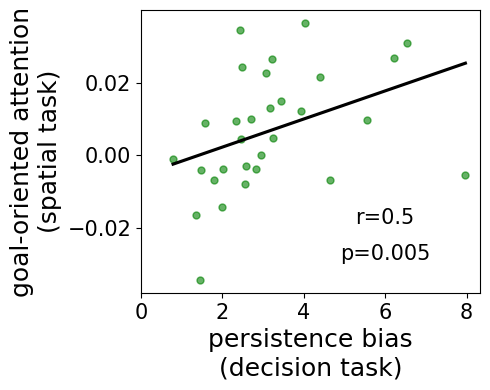

In [12]:
# Plot correlation (fig.2g)

fig,axes = plt.subplots(figsize=[5,4])
# n.b. plot IP_S which is the indifference point from inside the scanner to plot separate sessions
sns.regplot(ax=axes,data=behavioural_params,x="IP_S",y="attention_bias",scatter_kws={"color":bias_color,'alpha':0.6,"s":25}, line_kws={"color": "black"},ci=None)   

# plotting params
axes.set_xlabel('persistence bias\n(decision task)',fontsize=medium_label_fontsize)
axes.set_ylabel('goal-oriented attention\n(spatial task)',fontsize=medium_label_fontsize)
axes.set_xticks(np.arange(0,9,2))
axes.tick_params(axis='y', which='major', labelsize=small_label_fontsize)
axes.tick_params(axis='x', which='major', labelsize=small_label_fontsize)

# add signifiacne
text='r='+str(round(spatial_scan_IP_R,2))
text2='p='+str(round(spatial_scan_IP_p,3))
axes.text(6,-0.02, text, ha='center', va='bottom',fontsize=small_label_fontsize)
axes.text(6,-0.03, text2, ha='center', va='bottom',fontsize=small_label_fontsize)

fig.tight_layout()
fig.savefig(figure_folder+'IP_spatial_bias.png',bbox_inches='tight',dpi=300)

##### For reviewers: correlation between attention and model-free abandonment metric (supplementary fig.10b)

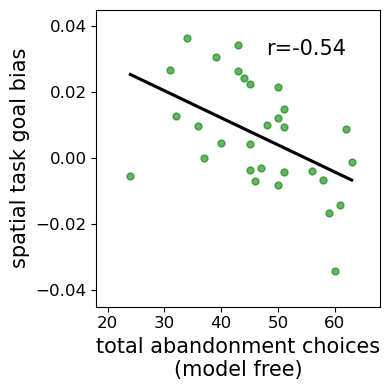

In [13]:
behavioural_params['total_switches'] = df_full.groupby('participant')['switch_trial'].sum()
fig,axes = plt.subplots(figsize=[4,4])
#sns.regplot(ax=axes,data=indiv_session_df,x="IP_S",y="attention_bias",scatter_kws={"color":bias_color,'alpha':0.6,"s":25}, line_kws={"color": "black"},ci=None)   
sns.regplot(ax=axes,data=behavioural_params,x="total_switches",y="attention_bias",scatter_kws={"color":bias_color,'alpha':0.6,"s":25}, line_kws={"color": "black"},ci=None)   
spatial_modelfree_R, spatial_modelfree_p = stats.spearmanr(behavioural_params["total_switches"], behavioural_params['attention_bias'])

# plotting params
axes.set_xlabel('total abandonment choices\n(model free)',fontsize=15)
axes.set_ylabel('spatial task goal bias',fontsize=15)
axes.set_xticks(np.arange(20,65,10))
axes.set_yticks(np.arange(-0.04,0.041,0.02))
axes.set_ylim([-0.045,0.045])
axes.set_xlim([18,68])
axes.tick_params(axis='y', which='major', labelsize=12)
axes.tick_params(axis='x', which='major', labelsize=12)

# add signifiacne
text='r='+str(round(spatial_modelfree_R,2))
text2='p='+str(round(spatial_modelfree_p,3))
axes.text(55,0.03, text, ha='center', va='bottom',fontsize=small_label_fontsize)

fig.tight_layout()
fig.savefig(figure_folder+'MF_attention_corr.png',dpi=300,bbox_inches='tight')

#### Correlation with baseline vmPFC activity

In [14]:
baseline_vmpfc = pd.read_csv(base_folder + '/data/mri_study/neural/baseline_vmpfc_activity.csv')

all_params = behavioural_params.copy()
all_params['neural_baseline_gp'] = baseline_vmpfc['baseline_vmpfc_gp']
r_neural_IP, p_neural_IP = stats.spearmanr(all_params["IP_combined_sessions"], all_params["neural_baseline_gp"])
print('persistence / baseline vmpfc: ' + str(r_neural_IP) + ', p=' + str(p_neural_IP))
r_neural_attention, p_neural_attention = stats.spearmanr(all_params["attention_bias"], all_params["neural_baseline_gp"])
print('attention / baseline vmpfc: ' + str(r_neural_attention) + ', p=' + str(p_neural_attention))

persistence / baseline vmpfc: 0.4593993325917686, p=0.010653164356950604
attention / baseline vmpfc: 0.4843159065628476, p=0.006687179946541406


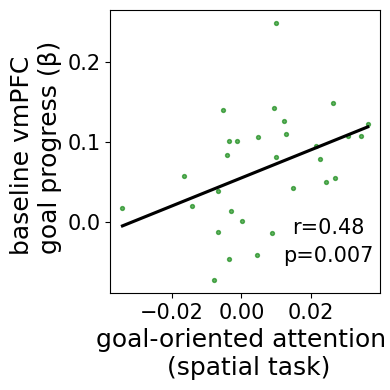

In [15]:
# Plot
fig,axes = plt.subplots(figsize=[4,4])

sns.regplot(ax=axes,data=all_params,x="attention_bias",y="neural_baseline_gp",scatter_kws={"color":bias_color,'alpha':0.6,"s":8}, line_kws={"color": "black"},ci=None)   

#sns.regplot(ax=axes,data=individual_table,x="indifference_points",y="errDiff_net_avg",scatter_kws={"color": "black"}, line_kws={"color": "blue"})   
axes.set_xlabel('goal-oriented attention \n (spatial task)',fontsize=medium_label_fontsize)
axes.set_ylabel('baseline vmPFC \n goal progress (β)',fontsize=medium_label_fontsize)
text='r='+str(np.round(r_neural_attention,2))
text2='p='+str(np.round(p_neural_attention,3))
axes.text(0.025,-0.02, text, ha='center', va='bottom',fontsize=small_label_fontsize)
axes.text(0.025,-0.055, text2, ha='center', va='bottom',fontsize=small_label_fontsize)

axes.set_yticks([0,0.1,0.2])
axes.tick_params(axis='y', which='major', labelsize=small_label_fontsize)
axes.tick_params(axis='x', which='major', labelsize=small_label_fontsize)


fig.tight_layout()
fig.savefig(figure_folder+'vmpfc_attention',bbox_inches='tight',dpi=300)

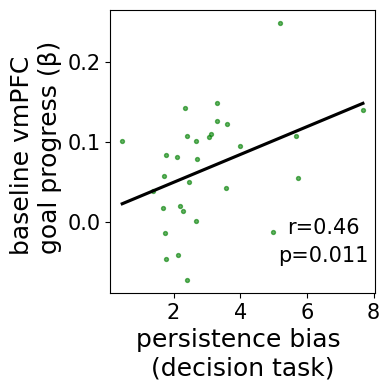

In [16]:
fig,axes = plt.subplots(figsize=[4,4])

sns.regplot(ax=axes,data=all_params,x="IP_combined_sessions",y="neural_baseline_gp",scatter_kws={"color":bias_color,'alpha':0.6,"s":8}, line_kws={"color": "black"},ci=None)   

#sns.regplot(ax=axes,data=individual_table,x="indifference_points",y="errDiff_net_avg",scatter_kws={"color": "black"}, line_kws={"color": "blue"})   
axes.set_xlabel('persistence bias \n(decision task)',fontsize=medium_label_fontsize)
axes.set_ylabel('baseline vmPFC \n goal progress (β)',fontsize=medium_label_fontsize)
text='r='+str(np.round(r_neural_IP,2))
text2='p='+str(np.round(p_neural_IP,3))
axes.text(6.5,-0.02, text, ha='center', va='bottom',fontsize=small_label_fontsize)
axes.text(6.5,-0.055, text2, ha='center', va='bottom',fontsize=small_label_fontsize)

axes.set_yticks([0,0.1,0.2])
axes.tick_params(axis='y', which='major', labelsize=small_label_fontsize)
axes.tick_params(axis='x', which='major', labelsize=small_label_fontsize)


fig.tight_layout()
fig.savefig(figure_folder+'vmpfc_decision',bbox_inches='tight',dpi=300)